SYNTHETIC PRACTICE DATA ONLY
Dataset shape: (330, 14)


,Request_ID,Service_Type,Requester_Type,Submission_Date,Requested_Channel,Priority,Assigned_Office,Queue_Length,Required_Documents_Complete,Processing_Days,SLA_Days,Status,Reopened,Satisfaction_Score
0,SYN0001,Scholarship Inquiry,Staff,2025-01-01,Portal,Normal,Scholarship Office,8,Yes,4.0,5,Completed,No,4.0
1,SYN0002,Certification,Staff,2025-01-02,Portal,Normal,Registrar,7,No,7.0,7,Completed,No,4.0
2,SYN0003,Enrollment Assistance,Student,2025-01-03,Email,Normal,Student Affairs,8,No,6.0,7,Completed,No,4.0
3,SYN0004,IT Support,Student,2025-01-04,Portal,High,IT Office,8,Yes,NaN,3,Pending,Yes,4.0
4,SYN0005,Records,Student,2025-01-05,Portal,Low,Student Affairs,6,No,2.0,2,Completed,No,5.0
5,SYN0006,Enrollment Assistance,Student,2025-01-06,Email,Normal,Registrar,11,No,3.0,2,Completed,No,1.0
6,SYN0007,Scholarship Inquiry,Student,2025-01-07,Email,Low,Scholarship Office,15,Yes,2.0,2,Completed,No,NaN
7,SYN0008,Scholarship Inquiry,Student,2025-01-08,Email,Normal,Scholarship Office,6,Yes,7.0,7,Completed,No,2.0
8,SYN0009,Records,Student,2025-01-09,Portal,Low,Registrar,4,Yes,10.0,7,Completed,No,4.0
9,SYN0010,Certification,Student,2025-01-10,Email,High,Registrar,11,Yes,3.0,5,Completed,No,4.0



DATA TYPES
Request_ID                      object
Service_Type                    object
Requester_Type                  object
Submission_Date                 object
Requested_Channel               object
Priority                        object
Assigned_Office                 object
Queue_Length                     int64
Required_Documents_Complete     object
Processing_Days                float64
SLA_Days                         int64
Status                          object
Reopened                        object
Satisfaction_Score             float64
dtype: object

MISSING VALUES
Request_ID                      0
Service_Type                    0
Requester_Type                  0
Submission_Date                 0
Requested_Channel               4
Priority                        0
Assigned_Office                 0
Queue_Length                    0
Required_Documents_Complete     6
Processing_Days                63
SLA_Days                        0
Status                          0
Reop

,Issue,Column,Count,Treatment
0,Missing values,Requested_Channel,4,Retained; handled where needed
1,Missing values,Required_Documents_Complete,6,Retained; handled where needed
2,Missing values,Processing_Days,63,Retained; handled where needed
3,Missing values,Satisfaction_Score,33,Retained; handled where needed
4,Exact duplicate rows,All,0,Removed exact duplicate rows


Eligible completed records: 267

REQUEST COUNT BY SERVICE TYPE


,count
Service_Type,
Records,94
Certification,77
IT Support,66
Scholarship Inquiry,49
Enrollment Assistance,44



SLA BREACH RATE BY OFFICE


,mean,count,Breach_Rate_Percent
Assigned_Office,,,
IT Office,0.461538,52,46.153846
Student Affairs,0.378378,74,37.837838
Registrar,0.360825,97,36.082474
Scholarship Office,0.318182,44,31.818182



SLA BREACH RATE BY QUEUE CATEGORY


,mean,count,Breach_Rate_Percent
Queue_Category,,,
Low,0.200000,20,20.000000
Medium,0.387931,232,38.793103
High,0.466667,15,46.666667


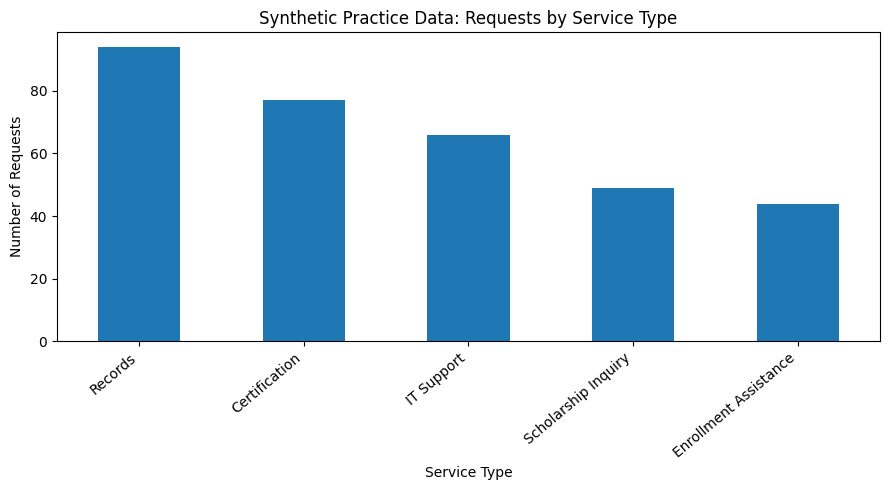

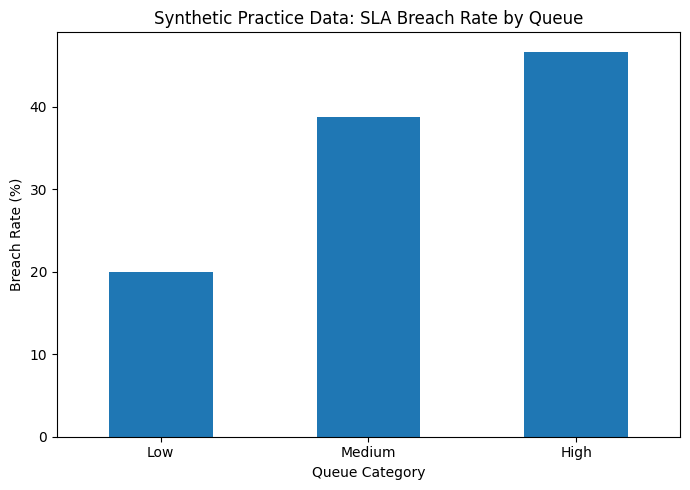


CONFUSION MATRIX (rows=actual, columns=predicted; labels 0,1)
[[17 17]
 [11  9]]

MODEL EVALUATION


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.481,0.346,0.45,0.391
1,Majority Baseline,0.630,0.000,0.00,0.000



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.61      0.50      0.55        34
           1       0.35      0.45      0.39        20

    accuracy                           0.48        54
   macro avg       0.48      0.47      0.47        54
weighted avg       0.51      0.48      0.49        54


TOP 10 FEATURE IMPORTANCES


,Feature,Importance
0,numeric__Queue_Length,0.281338
24,categorical__Submission_Weekday_Saturday,0.076097
11,categorical__Requested_Channel_Portal,0.069735
16,categorical__Assigned_Office_IT Office,0.062070
28,categorical__Submission_Weekday_Wednesday,0.060677
27,categorical__Submission_Weekday_Tuesday,0.053026
25,categorical__Submission_Weekday_Sunday,0.052215
15,categorical__Priority_Normal,0.048843
19,categorical__Assigned_Office_Student Affairs,0.048835
17,categorical__Assigned_Office_Registrar,0.044930


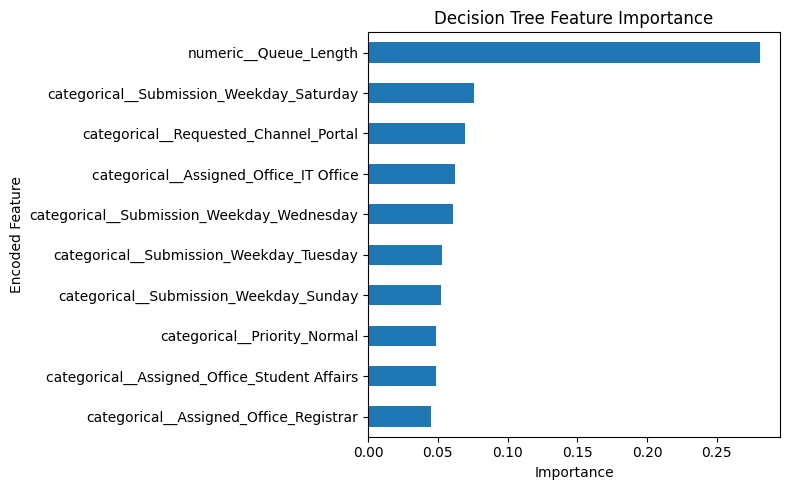

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
from IPython.display import display


np.random.seed(42)
rng = np.random.default_rng(42)
n = 330

service_types = [
    "Records", "Certification", "IT Support",
    "Scholarship Inquiry", "Enrollment Assistance"
]

service = rng.choice(
    service_types, n,
    p=[0.28, 0.22, 0.20, 0.14, 0.16]
)
priority = rng.choice(
    ["Low", "Normal", "High"], n,
    p=[0.20, 0.60, 0.20]
)
queue = rng.poisson(10, n).clip(0, 35)
required = rng.choice(["Yes", "No"], n, p=[0.86, 0.14])
sla = rng.choice([2, 3, 5, 7], n)

office = []
for s in service:
    if s in ["Records", "Certification", "Enrollment Assistance"]:
        office.append(rng.choice(["Registrar", "Student Affairs"]))
    elif s == "IT Support":
        office.append("IT Office")
    else:
        office.append("Scholarship Office")


logit = (
    -2.1 + 0.10 * queue
    + 0.65 * (priority == "High")
    + 0.75 * (required == "No")
)
breach_simulated = rng.binomial(
    1, 1 / (1 + np.exp(-logit))
)
noise = rng.normal(0, 1.4, n)
processing = np.maximum(
    1,
    np.rint(
        sla + np.where(breach_simulated == 1, 2, -1) + noise
    )
).astype(int)

status = rng.choice(
    ["Completed", "Pending", "Cancelled"],
    n, p=[0.78, 0.17, 0.05]
)
processing_days = [
    float(processing[i]) if status[i] == "Completed" else np.nan
    for i in range(n)
]

df = pd.DataFrame({
    "Request_ID": [f"SYN{i+1:04d}" for i in range(n)],
    "Service_Type": service,
    "Requester_Type": rng.choice(
        ["Student", "Faculty", "Staff"], n,
        p=[0.82, 0.10, 0.08]
    ),
    "Submission_Date": pd.date_range(
        "2025-01-01", periods=n, freq="D"
    ).strftime("%Y-%m-%d"),
    "Requested_Channel": rng.choice(
        ["Portal", "Email", "Walk-in"], n,
        p=[0.65, 0.23, 0.12]
    ),
    "Priority": priority,
    "Assigned_Office": office,
    "Queue_Length": queue,
    "Required_Documents_Complete": required,
    "Processing_Days": processing_days,
    "SLA_Days": sla,
    "Status": status,
    "Reopened": rng.choice(["Yes", "No"], n, p=[0.08, 0.92]),
    "Satisfaction_Score": rng.choice(
        [1, 2, 3, 4, 5, np.nan], n,
        p=[0.03, 0.05, 0.10, 0.36, 0.35, 0.11]
    )
})


for col, probability in [
    ("Required_Documents_Complete", 0.02),
    ("Requested_Channel", 0.015)
]:
    mask = rng.random(n) < probability
    df.loc[mask, col] = np.nan

print("SYNTHETIC PRACTICE DATA ONLY")
print("Dataset shape:", df.shape)
display(df.head(10))


print("\nDATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

for col in df.select_dtypes(include="object").columns:
    print(f"\nFrequency: {col}")
    print(df[col].value_counts(dropna=False))


clean = df.copy()
clean.columns = clean.columns.str.strip()

for col in clean.select_dtypes(include="object").columns:
    clean[col] = clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

quality_log = []

for col in clean.columns:
    missing = int(clean[col].isna().sum())
    if missing:
        quality_log.append({
            "Issue": "Missing values",
            "Column": col,
            "Count": missing,
            "Treatment": "Retained; handled where needed"
        })

duplicate_count = int(clean.duplicated().sum())
clean = clean.drop_duplicates()

quality_log.append({
    "Issue": "Exact duplicate rows",
    "Column": "All",
    "Count": duplicate_count,
    "Treatment": "Removed exact duplicate rows"
})

clean["Submission_Date"] = pd.to_datetime(
    clean["Submission_Date"], errors="coerce"
)

print("\nDuplicate Request_ID rows:",
      clean["Request_ID"].duplicated(keep=False).sum())
print("Missing/invalid dates:",
      clean["Submission_Date"].isna().sum())


for col in clean.select_dtypes(include=np.number).columns:
    negative = int((clean[col] < 0).sum())
    if negative:
        quality_log.append({
            "Issue": "Negative numeric values",
            "Column": col,
            "Count": negative,
            "Treatment": "Set to missing for review"
        })
        clean.loc[clean[col] < 0, col] = np.nan


clean["Submission_Weekday"] = clean["Submission_Date"].dt.day_name()

clean["Queue_Category"] = pd.cut(
    clean["Queue_Length"],
    bins=[-np.inf, 5, 15, np.inf],
    labels=["Low", "Medium", "High"]
)

eligible = (
    clean["Status"].eq("Completed")
    & clean["Processing_Days"].notna()
    & clean["SLA_Days"].notna()
)

clean["SLA_Breached"] = np.nan
clean.loc[eligible, "SLA_Breached"] = (
    clean.loc[eligible, "Processing_Days"]
    > clean.loc[eligible, "SLA_Days"]
).astype(int)

pd.DataFrame(quality_log).to_csv(
    "data_quality_log.csv", index=False
)
clean.to_csv("cleaned_student_service_requests.csv", index=False)

print("\nQUALITY LOG")
display(pd.DataFrame(quality_log))
print("Eligible completed records:", int(eligible.sum()))


labeled = clean.loc[clean["SLA_Breached"].notna()].copy()

print("\nREQUEST COUNT BY SERVICE TYPE")
service_counts = clean["Service_Type"].value_counts()
display(service_counts)

print("\nSLA BREACH RATE BY OFFICE")
office_stats = labeled.groupby(
    "Assigned_Office"
)["SLA_Breached"].agg(["mean", "count"])

office_stats["Breach_Rate_Percent"] = office_stats["mean"] * 100
display(office_stats.sort_values(
    "Breach_Rate_Percent", ascending=False
))

print("\nSLA BREACH RATE BY QUEUE CATEGORY")
queue_stats = labeled.groupby(
    "Queue_Category", observed=True
)["SLA_Breached"].agg(["mean", "count"])

queue_stats["Breach_Rate_Percent"] = queue_stats["mean"] * 100
display(queue_stats)

service_counts.plot(kind="bar", figsize=(9, 5))
plt.title("Synthetic Practice Data: Requests by Service Type")
plt.xlabel("Service Type")
plt.ylabel("Number of Requests")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("chart1_service_volume.png", dpi=150)
plt.show()


queue_stats["Breach_Rate_Percent"].plot(
    kind="bar", figsize=(7, 5)
)
plt.title("Synthetic Practice Data: SLA Breach Rate by Queue")
plt.xlabel("Queue Category")
plt.ylabel("Breach Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart2_queue_breach_rate.png", dpi=150)
plt.show()


features = [
    "Service_Type",
    "Requester_Type",
    "Requested_Channel",
    "Priority",
    "Assigned_Office",
    "Queue_Length",
    "Required_Documents_Complete",
    "SLA_Days",
    "Submission_Weekday",
    "Queue_Category"
]

model_data = clean.loc[clean["SLA_Breached"].notna()].copy()
X = model_data[features]
y = model_data["SLA_Breached"].astype(int)

if len(y) < 5 or y.nunique() < 2:
    raise ValueError(
        "Not enough labeled records or only one target class. "
        "Check the dataset before training."
    )

categorical = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numerical = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numerical),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

stratify_arg = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_arg
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

def evaluate(name, actual, predicted):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1-score": f1_score(
            actual, predicted, zero_division=0
        )
    }

results = pd.DataFrame([
    evaluate("Decision Tree", y_test, pred),
    evaluate("Majority Baseline", y_test, baseline_pred)
])

print("\nCONFUSION MATRIX (rows=actual, columns=predicted; labels 0,1)")
print(confusion_matrix(y_test, pred, labels=[0, 1]))

print("\nMODEL EVALUATION")
display(results.round(3))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, pred, zero_division=0))


feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

importances = model.named_steps[
    "classifier"
].feature_importances_

importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("\nTOP 10 FEATURE IMPORTANCES")
display(importance_table.head(10))

importance_table.head(10).sort_values("Importance").plot(
    x="Feature", y="Importance",
    kind="barh", legend=False, figsize=(8, 5)
)
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Encoded Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

files_to_zip = [
    "cleaned_student_service_requests.csv",
    "data_quality_log.csv",
    "chart1_service_volume.png",
    "chart2_queue_breach_rate.png",
    "feature_importance.png"
]

with zipfile.ZipFile(
    "SectionB_Practice_Outputs.zip", "w"
) as zipf:
    for filename in files_to_zip:
        if os.path.exists(filename):
            zipf.write(filename)


df.to_csv("student_service_requests_330_synthetic.csv", index=False)


from google.colab import files
files.download("student_service_requests_330_synthetic.csv")
files.download("SectionB_Practice_Outputs.zip")


In [ ]:

from google.colab import files

files.download("student_service_requests_330_synthetic.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>